# Question 1 – Working with NumPy Arrays
## Scenario: Multidimensional Student Performance Analysis

Marks of **20 postgraduate students** in **5 courses**: Python, Statistics, Data Visualization, ML and Research Methods.

| Task | Description | Marks |
|---|---|---|
| a | Create a multidimensional NumPy array; analyse dimensions, shape, data type and memory | 10 |
| b | Slicing, indexing, reshaping and vectorized operations | 15 |
| c | Student-wise totals, means, medians, standard deviations | 15 |
| d | Subject-wise averages, best and most variable subjects, ranking students | 15 |
| e | Students scoring below 50 in any subject / average below 60 | 10 |
| f | Min-Max normalization and Z-score standardization, compared | 15 |
| g | Visualize subject-wise performance | 10 |
| h | Interpretation and academic interventions | 10 |

> **How to use this notebook:** run the cells from top to bottom (*Kernel → Restart & Run All* in Jupyter, *Runtime → Run all* in Colab). Every library used here is pre-installed in Google Colab and in Anaconda.
>
> **Exam tip:** if the exam gives different marks, only change the data cell in Step 0 — the rest of the code recalculates automatically. Re-read the printed outputs before writing your interpretation.

## Step 0 – Import libraries and enter the data

* **NumPy** does all the numerical work (this is a NumPy question).
* **pandas** is used *only* to print results as neat labelled tables.
* **matplotlib** draws the plots.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Show at most 2 decimal places when printing arrays (makes output easier to read)
np.set_printoptions(precision=2, suppress=True)

# Labels for rows (students) and columns (subjects)
students = np.array([f"S{i}" for i in range(1, 21)])          # 'S1' ... 'S20'
subjects = np.array(["Python", "Statistics", "Data Visualization", "ML", "Research Methods"])

# The marks: one row per student, one column per subject
marks = np.array([
    [78, 82, 85, 74, 88],   # S1
    [65, 70, 68, 72, 75],   # S2
    [90, 92, 88, 95, 91],   # S3
    [55, 60, 58, 62, 65],   # S4
    [72, 75, 78, 80, 77],   # S5
    [84, 86, 89, 82, 87],   # S6
    [68, 72, 70, 75, 73],   # S7
    [92, 88, 95, 90, 94],   # S8
    [76, 79, 81, 78, 80],   # S9
    [60, 65, 63, 68, 70],   # S10
    [81, 84, 79, 86, 83],   # S11
    [73, 69, 75, 72, 78],   # S12
    [88, 91, 90, 87, 92],   # S13
    [49, 55, 52, 58, 60],   # S14
    [67, 74, 71, 69, 76],   # S15
    [95, 93, 97, 94, 96],   # S16
    [71, 77, 74, 79, 73],   # S17
    [83, 80, 85, 88, 84],   # S18
    [58, 62, 60, 65, 63],   # S19
    [86, 89, 84, 91, 88],   # S20
], dtype=np.int64)   # dtype fixed to int64 so results are identical on Windows, Linux, Mac and Colab

print(marks)

[[78 82 85 74 88]
 [65 70 68 72 75]
 [90 92 88 95 91]
 [55 60 58 62 65]
 [72 75 78 80 77]
 [84 86 89 82 87]
 [68 72 70 75 73]
 [92 88 95 90 94]
 [76 79 81 78 80]
 [60 65 63 68 70]
 [81 84 79 86 83]
 [73 69 75 72 78]
 [88 91 90 87 92]
 [49 55 52 58 60]
 [67 74 71 69 76]
 [95 93 97 94 96]
 [71 77 74 79 73]
 [83 80 85 88 84]
 [58 62 60 65 63]
 [86 89 84 91 88]]


## (a) Create a multidimensional array and analyse its properties  *(10 marks)*

A NumPy `ndarray` has these key attributes:

| Attribute | Meaning |
|---|---|
| `ndim` | number of dimensions (axes) |
| `shape` | size along each axis → (rows, columns) |
| `size` | total number of elements = rows × columns |
| `dtype` | data type of every element (all elements share one type) |
| `itemsize` | bytes used by **one** element |
| `nbytes` | bytes used by **all** elements = `size × itemsize` |

Axis convention used throughout: **axis 0 = down the rows (students)**, **axis 1 = across the columns (subjects)**.

In [2]:
print("Number of dimensions (ndim):", marks.ndim)
print("Shape (students, subjects) :", marks.shape)
print("Total elements (size)      :", marks.size)
print("Data type (dtype)          :", marks.dtype)
print("Bytes per element (itemsize):", marks.itemsize)
print("Total memory (nbytes)      :", marks.nbytes, "bytes")
print("Check: size x itemsize     =", marks.size * marks.itemsize, "bytes")

Number of dimensions (ndim): 2
Shape (students, subjects) : (20, 5)
Total elements (size)      : 100
Data type (dtype)          : int64
Bytes per element (itemsize): 8
Total memory (nbytes)      : 800 bytes
Check: size x itemsize     = 800 bytes


**Memory comparison with other data types.** Marks are whole numbers from 0–100, so a smaller integer type is enough. Choosing the right dtype saves memory, which matters for large datasets.

In [3]:
for dt in [np.int64, np.int32, np.int16, np.int8, np.float64]:
    a = marks.astype(dt)
    print(f"{str(a.dtype):8s} -> itemsize = {a.itemsize} byte(s), total = {a.nbytes:4d} bytes")

# int8 can store -128..127, which is enough for marks 0..100
marks_small = marks.astype(np.int8)
print("\nMemory saved by using int8 instead of int64:", marks.nbytes - marks_small.nbytes, "bytes",
      f"({(1 - marks_small.nbytes / marks.nbytes) * 100:.1f}% less)")

int64    -> itemsize = 8 byte(s), total =  800 bytes
int32    -> itemsize = 4 byte(s), total =  400 bytes
int16    -> itemsize = 2 byte(s), total =  200 bytes
int8     -> itemsize = 1 byte(s), total =  100 bytes
float64  -> itemsize = 8 byte(s), total =  800 bytes

Memory saved by using int8 instead of int64: 700 bytes (87.5% less)


**Going to 3 dimensions.** A 2-D array is already multidimensional, but we can also build a **3-D** array. Example: imagine the 20 students are split into **4 batches of 5 students** each → shape `(4 batches, 5 students, 5 subjects)`.

In [4]:
marks_3d = marks.reshape(4, 5, 5)   # 4 x 5 x 5 = 100 elements, same as 20 x 5

print("3-D shape:", marks_3d.shape, "| ndim:", marks_3d.ndim, "| size:", marks_3d.size)
print("\nBatch 1 (students S1-S5):\n", marks_3d[0])
print("\nAverage of each subject inside each batch (rows = batch, cols = subject):")
print(marks_3d.mean(axis=1))

3-D shape: (4, 5, 5) | ndim: 3 | size: 100

Batch 1 (students S1-S5):
 [[78 82 85 74 88]
 [65 70 68 72 75]
 [90 92 88 95 91]
 [55 60 58 62 65]
 [72 75 78 80 77]]

Average of each subject inside each batch (rows = batch, cols = subject):
[[72.  75.8 75.4 76.6 79.2]
 [76.  78.  79.6 78.6 80.8]
 [71.6 74.6 73.4 74.4 77.8]
 [78.6 80.2 80.  83.4 80.8]]


## (b) Slicing, indexing, reshaping and vectorized operations  *(15 marks)*

* **Indexing** – `marks[row, col]` picks one element (indices start at 0).
* **Slicing** – `marks[start:stop, start:stop]` picks a block (stop is *excluded*).
* **Fancy indexing** – pass a list of positions, e.g. `marks[[0, 2, 4]]`.
* **Boolean indexing** – pass a True/False mask, e.g. `marks[marks[:, 0] > 85]`.
* **Vectorized operations** – arithmetic is applied to every element at once, with no Python loop.

In [5]:
# Helper: find the position (index) of a subject or student by its name
def subj(name):
    return int(np.where(subjects == name)[0][0])

def stud(name):
    return int(np.where(students == name)[0][0])

# --- Basic indexing -----------------------------------------------------
print("1. Marks of S3 in ML              :", marks[stud("S3"), subj("ML")])   # row 2, col 3
print("2. All marks of student S8        :", marks[stud("S8")])               # whole row 7
print("3. Python marks of all students   :", marks[:, subj("Python")])        # whole column 0
print("4. Last student's (S20) marks     :", marks[-1])                       # negative index

1. Marks of S3 in ML              : 95
2. All marks of student S8        : [92 88 95 90 94]
3. Python marks of all students   : [78 65 90 55 72 84 68 92 76 60 81 73 88 49 67 95 71 83 58 86]
4. Last student's (S20) marks     : [86 89 84 91 88]


In [6]:
# --- Slicing ---------------------------------------------------------------
print("5. First 5 students, first 3 subjects (rows 0-4, cols 0-2):")
print(marks[:5, :3])

print("\n6. Students S11-S15, subjects Data Visualization to Research Methods:")
print(marks[10:15, 2:5])

print("\n7. Every alternate student (S1, S3, S5, ...) - Python marks only:")
print(marks[::2, 0])

5. First 5 students, first 3 subjects (rows 0-4, cols 0-2):
[[78 82 85]
 [65 70 68]
 [90 92 88]
 [55 60 58]
 [72 75 78]]

6. Students S11-S15, subjects Data Visualization to Research Methods:
[[79 86 83]
 [75 72 78]
 [90 87 92]
 [52 58 60]
 [71 69 76]]

7. Every alternate student (S1, S3, S5, ...) - Python marks only:
[78 90 72 68 76 81 88 67 71 58]


In [7]:
# --- Fancy indexing (a list of positions) -----------------------------------
selected = [stud(s) for s in ["S3", "S8", "S16"]]
print("8. Marks of S3, S8 and S16:")
print(marks[selected])

print("\n9. Only the Python and ML columns for those three students:")
print(marks[np.ix_(selected, [subj("Python"), subj("ML")])])   # np.ix_ picks rows x columns

8. Marks of S3, S8 and S16:
[[90 92 88 95 91]
 [92 88 95 90 94]
 [95 93 97 94 96]]

9. Only the Python and ML columns for those three students:
[[90 95]
 [92 90]
 [95 94]]


In [8]:
# --- Boolean indexing (a True/False mask) ------------------------------------
py = marks[:, subj("Python")]
mask = py > 85
print("10. Mask 'Python > 85':", mask)
print("    Students with Python > 85:", students[mask])
print("    Their Python marks       :", py[mask])

# Students who scored at least 80 in EVERY subject
all80 = np.all(marks >= 80, axis=1)
print("\n11. Students with >= 80 in all five subjects:", students[all80])

10. Mask 'Python > 85': [False False  True False False False False  True False False False False
  True False False  True False False False  True]
    Students with Python > 85: ['S3' 'S8' 'S13' 'S16' 'S20']
    Their Python marks       : [90 92 88 95 86]

11. Students with >= 80 in all five subjects: ['S3' 'S6' 'S8' 'S13' 'S16' 'S18' 'S20']


In [9]:
# --- Reshaping ----------------------------------------------------------------
flat = marks.flatten()            # 2-D -> 1-D copy of 100 values
print("12. Flattened shape:", flat.shape, "-> first 10 values:", flat[:10])

transposed = marks.T              # swap rows and columns: (5 subjects, 20 students)
print("13. Transposed shape:", transposed.shape)

back = flat.reshape(20, 5)        # 1-D -> back to 2-D
print("14. Reshaped back to", back.shape, "- identical to original?", np.array_equal(back, marks))

print("15. reshape(-1, 10) lets NumPy work out one dimension ->", marks.reshape(-1, 10).shape)

12. Flattened shape: (100,) -> first 10 values: [78 82 85 74 88 65 70 68 72 75]
13. Transposed shape: (5, 20)
14. Reshaped back to (20, 5) - identical to original? True
15. reshape(-1, 10) lets NumPy work out one dimension -> (10, 10)


In [10]:
# --- Vectorized operations (no loops) ----------------------------------------
# (i) Add 5 grace marks to everyone but never exceed 100
grace = np.clip(marks + 5, 0, 100)
print("16. After 5 grace marks (first 3 students):\n", grace[:3])

# (ii) Convert Python marks (out of 100) to a 10-point scale
print("\n17. Python marks on a 10-point scale:", marks[:, 0] / 10)

# (iii) Weighted score: each subject has a weight; weights add up to 1
weights = np.array([0.25, 0.20, 0.20, 0.20, 0.15])
weighted = marks @ weights          # matrix (20x5) times vector (5) -> 20 weighted scores
print("\n18. Weighted score of each student:", weighted)

# (iv) Broadcasting: subtract each subject's mean from its column
centered = marks - marks.mean(axis=0)   # shape (20,5) minus shape (5,) -> broadcast row-wise
print("\n19. Mean-centred marks (first 3 students):\n", centered[:3])

16. After 5 grace marks (first 3 students):
 [[ 83  87  90  79  93]
 [ 70  75  73  77  80]
 [ 95  97  93 100  96]]

17. Python marks on a 10-point scale: [7.8 6.5 9.  5.5 7.2 8.4 6.8 9.2 7.6 6.  8.1 7.3 8.8 4.9 6.7 9.5 7.1 8.3
 5.8 8.6]

18. Weighted score of each student: [80.9  69.5  91.15 59.5  76.15 85.45 71.35 91.7  78.6  64.7  82.5  73.15
 89.4  54.25 70.95 94.95 74.7  83.95 61.35 87.5 ]

19. Mean-centred marks (first 3 students):
 [[ 3.45  4.85  7.9  -4.25  8.35]
 [-9.55 -7.15 -9.1  -6.25 -4.65]
 [15.45 14.85 10.9  16.75 11.35]]


**Why vectorization?** The same calculation with a Python loop is much slower. Quick check:

In [11]:
import time
big = np.random.default_rng(0).integers(0, 101, size=(1_000_000, 5))

t0 = time.perf_counter()
loop_totals = [sum(row) for row in big.tolist()]        # pure Python loop
t1 = time.perf_counter()
vec_totals = big.sum(axis=1)                            # vectorized NumPy
t2 = time.perf_counter()

print(f"Python loop : {t1 - t0:.3f} s")
print(f"NumPy       : {t2 - t1:.4f} s")
print("Same result?", np.array_equal(np.array(loop_totals), vec_totals))

Python loop : 0.454 s
NumPy       : 0.0196 s
Same result? True


## (c) Student-wise totals, means, medians and standard deviations  *(15 marks)*

"Student-wise" means one value **per row**, so we use **`axis=1`** (operate across the columns of each row).

> **Standard deviation note:** `np.std` uses the *population* formula (divide by *n*, `ddof=0`) by default. Use `ddof=1` for the *sample* formula (divide by *n − 1*). Here each student's 5 marks are the complete set of their marks, so the population SD (`ddof=0`) is reported; the sample SD is shown alongside for completeness. State which one you use in the exam.

In [12]:
student_total  = marks.sum(axis=1)
student_mean   = marks.mean(axis=1)
student_median = np.median(marks, axis=1)
student_sd     = marks.std(axis=1)            # population SD (ddof=0)
student_sd_s   = marks.std(axis=1, ddof=1)    # sample SD     (ddof=1)

student_stats = pd.DataFrame({
    "Total (/500)": student_total,
    "Mean": student_mean,
    "Median": student_median,
    "SD (ddof=0)": student_sd.round(2),
    "SD (ddof=1)": student_sd_s.round(2),
    "Min": marks.min(axis=1),
    "Max": marks.max(axis=1),
}, index=students)
display(student_stats)

,Total (/500),Mean,Median,SD (ddof=0),SD (ddof=1),Min,Max
S1,407,81.4,82.0,4.96,5.55,74,88
S2,350,70.0,70.0,3.41,3.81,65,75
S3,456,91.2,91.0,2.32,2.59,88,95
S4,300,60.0,60.0,3.41,3.81,55,65
S5,382,76.4,77.0,2.73,3.05,72,80
S6,428,85.6,86.0,2.42,2.70,82,89
S7,358,71.6,72.0,2.42,2.70,68,75
S8,459,91.8,92.0,2.56,2.86,88,95
S9,394,78.8,79.0,1.72,1.92,76,81
S10,326,65.2,65.0,3.54,3.96,60,70


In [13]:
print("Highest total :", students[np.argmax(student_total)], "with", student_total.max())
print("Lowest total  :", students[np.argmin(student_total)], "with", student_total.min())
print("Most consistent student (smallest SD):", students[np.argmin(student_sd)], f"(SD = {student_sd.min():.2f})")
print("Least consistent student (largest SD):", students[np.argmax(student_sd)], f"(SD = {student_sd.max():.2f})")
print(f"Class average of student means: {student_mean.mean():.2f}")

Highest total : S16 with 475
Lowest total  : S14 with 274
Most consistent student (smallest SD): S16 (SD = 1.41)
Least consistent student (largest SD): S1 (SD = 4.96)
Class average of student means: 77.34


## (d) Subject-wise averages, best & most variable subjects, ranking  *(15 marks)*

"Subject-wise" means one value **per column**, so we use **`axis=0`**.

* **Highest-performing subject** → highest mean mark.
* **Most variable subject** → largest standard deviation. Because the subject means are of similar size, SD is a fair comparison; the **coefficient of variation** `CV = SD / mean × 100` is also shown as a scale-free check.

In [14]:
subj_mean   = marks.mean(axis=0)
subj_median = np.median(marks, axis=0)
subj_sd     = marks.std(axis=0, ddof=1)       # sample SD: 20 students are a sample of all students
subj_cv     = subj_sd / subj_mean * 100

subject_stats = pd.DataFrame({
    "Mean": subj_mean,
    "Median": subj_median,
    "SD (ddof=1)": subj_sd.round(2),
    "CV (%)": subj_cv.round(2),
    "Min": marks.min(axis=0),
    "Max": marks.max(axis=0),
    "Range": np.ptp(marks, axis=0),
}, index=subjects)
display(subject_stats)

print("Highest-performing subject:", subjects[np.argmax(subj_mean)], f"(mean = {subj_mean.max():.2f})")
print("Lowest-performing subject :", subjects[np.argmin(subj_mean)], f"(mean = {subj_mean.min():.2f})")
print("Most variable subject (SD):", subjects[np.argmax(subj_sd)], f"(SD = {subj_sd.max():.2f}, CV = {subj_cv[np.argmax(subj_sd)]:.2f}%)")
print("Least variable subject    :", subjects[np.argmin(subj_sd)], f"(SD = {subj_sd.min():.2f})")

,Mean,Median,SD (ddof=1),CV (%),Min,Max,Range
Python,74.55,74.5,13.02,17.47,49,95,46
Statistics,77.15,78.0,11.24,14.58,55,93,38
Data Visualization,77.10,78.5,12.58,16.31,52,97,45
ML,78.25,78.5,10.82,13.83,58,95,37
Research Methods,79.65,79.0,10.47,13.14,60,96,36


Highest-performing subject: Research Methods (mean = 79.65)
Lowest-performing subject : Python (mean = 74.55)
Most variable subject (SD): Python (SD = 13.02, CV = 17.47%)
Least variable subject    : Research Methods (SD = 10.47)


**Ranking students.** `np.argsort` returns the positions that would sort the array in ascending order; reversing it (`[::-1]`) gives descending order. Rank 1 = highest total. We also check for ties (two students with the same total share the same rank under "competition ranking").

In [15]:
order = np.argsort(-student_total, kind="stable")    # positions sorted by total, highest first

# Competition ranking (1, 2, 2, 4 ...) so tied totals share a rank
comp_rank = np.array([1 + np.sum(student_total > t) for t in student_total])

ranking = pd.DataFrame({
    "Student": students[order],
    "Total": student_total[order],
    "Mean": student_mean[order],
    "Rank": comp_rank[order],
})
ranking.index = np.arange(1, 21)
display(ranking)

values, counts = np.unique(student_total, return_counts=True)
ties = values[counts > 1]
print("Tied totals:", ties if ties.size else "none - every student has a unique rank")

,Student,Total,Mean,Rank
1,S16,475,95.0,1
2,S8,459,91.8,2
3,S3,456,91.2,3
4,S13,448,89.6,4
5,S20,438,87.6,5
6,S6,428,85.6,6
7,S18,420,84.0,7
8,S11,413,82.6,8
9,S1,407,81.4,9
10,S9,394,78.8,10


Tied totals: none - every student has a unique rank


In [16]:
# Rank within each subject as well (who topped each subject?)
for j, s in enumerate(subjects):
    col = marks[:, j]
    top = students[col == col.max()]
    low = students[col == col.min()]
    print(f"{s:20s} topper: {', '.join(top)} ({col.max()})   lowest: {', '.join(low)} ({col.min()})")

Python               topper: S16 (95)   lowest: S14 (49)
Statistics           topper: S16 (93)   lowest: S14 (55)
Data Visualization   topper: S16 (97)   lowest: S14 (52)
ML                   topper: S3 (95)   lowest: S14 (58)
Research Methods     topper: S16 (96)   lowest: S14 (60)


## (e) Students below 50 in any subject, and students with average below 60  *(10 marks)*

* `marks < 50` gives a True/False matrix.
* `np.any(..., axis=1)` → True if **at least one** subject in that row is below 50.
* `student_mean < 60` → True if the average is below 60.

In [17]:
below50_mask = np.any(marks < 50, axis=1)
print("Students scoring below 50 in at least one subject:", students[below50_mask])
for i in np.where(below50_mask)[0]:
    failed = subjects[marks[i] < 50]
    print(f"   {students[i]}: below 50 in {', '.join(failed)} -> mark(s) {marks[i][marks[i] < 50]}")

avg_below60 = student_mean < 60
print("\nStudents whose average is below 60:", students[avg_below60], "->", student_mean[avg_below60])

both = below50_mask & avg_below60
print("Students in BOTH groups (highest risk):", students[both])

Students scoring below 50 in at least one subject: ['S14']
   S14: below 50 in Python -> mark(s) [49]

Students whose average is below 60: ['S14'] -> [54.8]
Students in BOTH groups (highest risk): ['S14']


In [18]:
# 'Borderline' students: average below 65 (close to the cut-off) - useful for part (h)
borderline = (student_mean >= 60) & (student_mean < 65)
print("Borderline students (60 <= average < 65):")
for i in np.where(borderline)[0]:
    print(f"   {students[i]}: average {student_mean[i]:.1f}, lowest mark {marks[i].min()} in {subjects[marks[i].argmin()]}")

Borderline students (60 <= average < 65):
   S4: average 60.0, lowest mark 55 in Python
   S19: average 61.6, lowest mark 58 in Python


## (f) Min-Max normalization vs Z-score standardization  *(15 marks)*

Both are applied **per subject (column-wise, axis=0)** so that every subject is put on the same scale.

| Method | Formula | Result |
|---|---|---|
| **Min-Max normalization** | $x' = \dfrac{x - x_{min}}{x_{max} - x_{min}}$ | values lie in **[0, 1]**; min → 0, max → 1 |
| **Z-score standardization** | $z = \dfrac{x - \mu}{\sigma}$ | mean **0**, SD **1**; tells how many SDs a mark is above/below the subject mean |

Here σ is the population SD (`ddof=0`), which is what `sklearn`'s `StandardScaler` also uses, so the standardized columns have SD exactly 1.

In [19]:
col_min, col_max = marks.min(axis=0), marks.max(axis=0)
minmax = (marks - col_min) / (col_max - col_min)       # broadcasting, column by column

col_mu, col_sigma = marks.mean(axis=0), marks.std(axis=0)   # ddof=0
zscore = (marks - col_mu) / col_sigma

display(pd.DataFrame(minmax.round(3), index=students, columns=subjects).head(8))
display(pd.DataFrame(zscore.round(3), index=students, columns=subjects).head(8))

,Python,Statistics,Data Visualization,ML,Research Methods
S1,0.630,0.711,0.733,0.432,0.778
S2,0.348,0.395,0.356,0.378,0.417
S3,0.891,0.974,0.800,1.000,0.861
S4,0.130,0.132,0.133,0.108,0.139
S5,0.500,0.526,0.578,0.595,0.472
S6,0.761,0.816,0.822,0.649,0.750
S7,0.413,0.447,0.400,0.459,0.361
S8,0.935,0.868,0.956,0.865,0.944


,Python,Statistics,Data Visualization,ML,Research Methods
S1,0.272,0.443,0.644,-0.403,0.818
S2,-0.752,-0.652,-0.742,-0.592,-0.456
S3,1.217,1.355,0.889,1.588,1.112
S4,-1.540,-1.565,-1.558,-1.540,-1.436
S5,-0.201,-0.196,0.073,0.166,-0.260
S6,0.744,0.807,0.971,0.355,0.720
S7,-0.516,-0.470,-0.579,-0.308,-0.652
S8,1.375,0.990,1.460,1.114,1.406


In [20]:
# Compare the properties of the two transformed datasets
compare = pd.DataFrame({
    "Original mean": marks.mean(axis=0), "Original SD": marks.std(axis=0),
    "MinMax min": minmax.min(axis=0), "MinMax max": minmax.max(axis=0),
    "MinMax mean": minmax.mean(axis=0), "MinMax SD": minmax.std(axis=0),
    "Z mean": zscore.mean(axis=0), "Z SD": zscore.std(axis=0),
    "Z min": zscore.min(axis=0), "Z max": zscore.max(axis=0),
}, index=subjects).round(3)
display(compare)

# The ORDER of students never changes - both are linear transformations
same_order = all(np.array_equal(np.argsort(marks[:, j], kind="stable"), np.argsort(minmax[:, j], kind="stable"))
                 and np.array_equal(np.argsort(marks[:, j], kind="stable"), np.argsort(zscore[:, j], kind="stable"))
                 for j in range(marks.shape[1]))
print("Ranking of students inside every subject is unchanged:", same_order)
print("Correlation between original and transformed Python marks:",
      round(np.corrcoef(marks[:, 0], minmax[:, 0])[0, 1], 6), "and", round(np.corrcoef(marks[:, 0], zscore[:, 0])[0, 1], 6))

,Original mean,Original SD,MinMax min,MinMax max,MinMax mean,MinMax SD,Z mean,Z SD,Z min,Z max
Python,74.55,12.694,0.0,1.0,0.555,0.276,0.0,1.0,-2.013,1.611
Statistics,77.15,10.960,0.0,1.0,0.583,0.288,-0.0,1.0,-2.021,1.446
Data Visualization,77.10,12.259,0.0,1.0,0.558,0.272,0.0,1.0,-2.047,1.623
ML,78.25,10.549,0.0,1.0,0.547,0.285,0.0,1.0,-1.920,1.588
Research Methods,79.65,10.204,0.0,1.0,0.546,0.283,-0.0,1.0,-1.926,1.602


Ranking of students inside every subject is unchanged: True
Correlation between original and transformed Python marks: 1.0 and 1.0


In [21]:
# Example: same raw mark (80) means different things in different subjects
for j, s in enumerate(subjects):
    z80 = (80 - col_mu[j]) / col_sigma[j]
    mm80 = (80 - col_min[j]) / (col_max[j] - col_min[j])
    print(f"A mark of 80 in {s:20s} -> Min-Max {mm80:.3f},  Z-score {z80:+.3f}")

A mark of 80 in Python               -> Min-Max 0.674,  Z-score +0.429
A mark of 80 in Statistics           -> Min-Max 0.658,  Z-score +0.260
A mark of 80 in Data Visualization   -> Min-Max 0.622,  Z-score +0.237
A mark of 80 in ML                   -> Min-Max 0.595,  Z-score +0.166
A mark of 80 in Research Methods     -> Min-Max 0.556,  Z-score +0.034


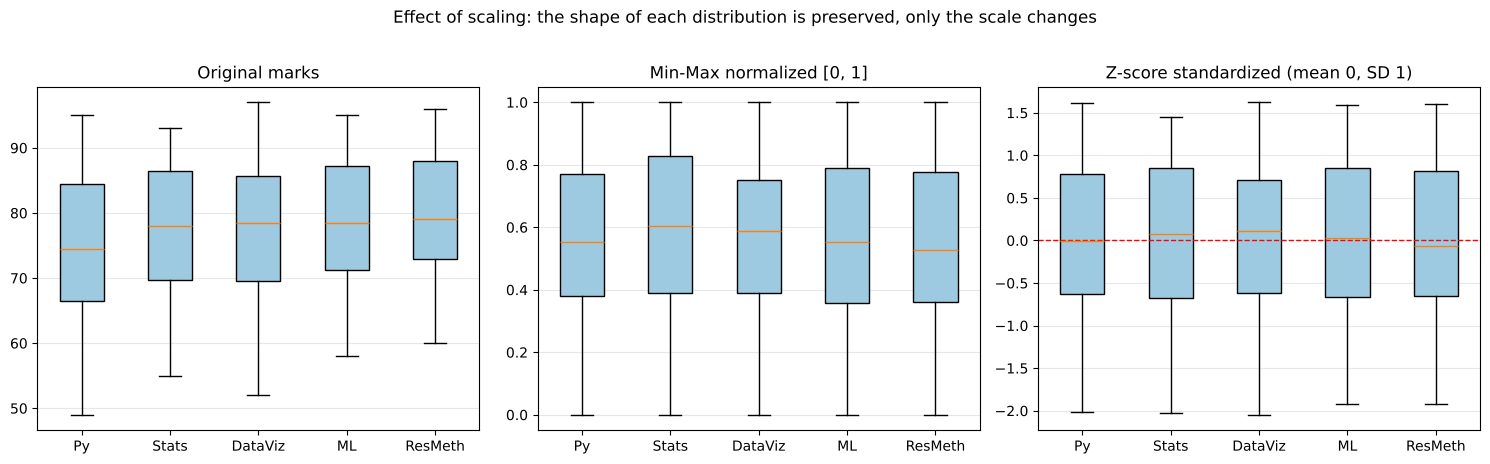

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for data, ax, title in zip([marks, minmax, zscore], axes,
                           ["Original marks", "Min-Max normalized [0, 1]", "Z-score standardized (mean 0, SD 1)"]):
    bp = ax.boxplot(data, patch_artist=True)
    for patch in bp["boxes"]:
        patch.set_facecolor("#9ecae1")
    ax.set_xticks(range(1, 6))
    ax.set_xticklabels(["Py", "Stats", "DataViz", "ML", "ResMeth"])
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)
axes[2].axhline(0, color="red", lw=1, ls="--")
plt.suptitle("Effect of scaling: the shape of each distribution is preserved, only the scale changes", y=1.02)
plt.tight_layout()
plt.show()

**Comparison of the two methods**

| Point | Min-Max normalization | Z-score standardization |
|---|---|---|
| Output range | Fixed **[0, 1]** | Not fixed (here about −2.05 to +1.62) |
| Centre / spread | Mean and SD differ by subject | Every subject has mean 0 and SD 1 |
| Sensitivity to outliers | **High** – one extreme mark sets min or max and squeezes all other values | Lower, although mean and SD are still affected by outliers |
| Interpretation | Position between the worst and best student | Number of SDs above or below the subject average |
| Shape and ranking | Unchanged (linear transformation) | Unchanged (linear transformation) |
| Typical use | Neural networks, image data, bounded inputs | PCA, regression, clustering, comparing across subjects |

**Effect on this data:** both methods keep the order of students and the shape of each distribution (the three box plots look identical apart from the y-axis). Only the scale changes, and the correlation between original and transformed marks is exactly 1.

Z-scores answer the question "how good is this mark *compared with classmates* in that subject?" A raw mark of 80 is worth **+0.43 SD** in Python (a harder subject, mean 74.55) but only **+0.03 SD** in Research Methods (mean 79.65). Raw marks hide this difference; standardized scores make subjects comparable. Min-Max values depend only on the single best and worst student in each subject, so one unusual mark would change every other value.

## (g) Visualize subject-wise performance  *(10 marks)*

Four complementary plots:
1. **Bar chart with error bars** – mean ± SD of each subject (compare averages and spread).
2. **Box plot** – median, quartiles and range of each subject (compare distributions).
3. **Heatmap** – every mark of every student (spot weak students/subjects at a glance).
4. **Line plot** – each student's profile across subjects (shows how consistent students are).

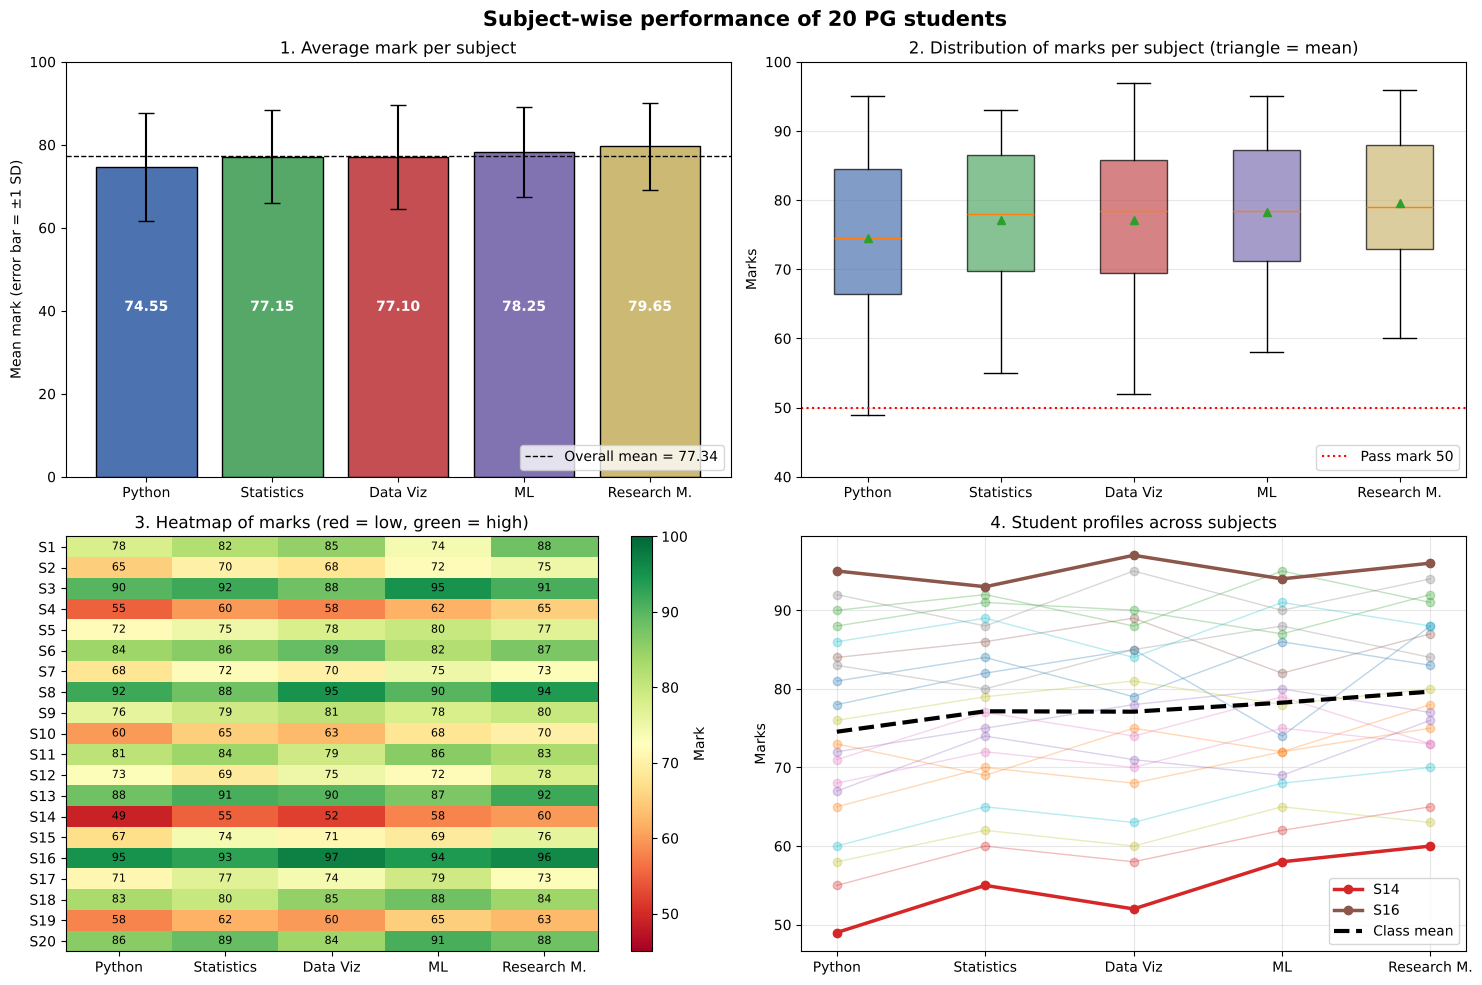

In [23]:
short = ["Python", "Statistics", "Data Viz", "ML", "Research M."]
colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Bar chart of subject means with SD error bars
ax = axes[0, 0]
bars = ax.bar(short, subj_mean, yerr=subj_sd, capsize=6, color=colors, edgecolor="black")
for b, m in zip(bars, subj_mean):
    ax.text(b.get_x() + b.get_width() / 2, 40, f"{m:.2f}", ha="center", color="white", fontweight="bold")
ax.axhline(marks.mean(), color="black", ls="--", lw=1, label=f"Overall mean = {marks.mean():.2f}")
ax.set_ylim(0, 100)
ax.set_ylabel("Mean mark (error bar = ±1 SD)")
ax.set_title("1. Average mark per subject")
ax.legend(loc="lower right")

# 2. Box plot of each subject
ax = axes[0, 1]
bp = ax.boxplot(marks, patch_artist=True, showmeans=True)
for patch, c in zip(bp["boxes"], colors):
    patch.set_facecolor(c)
    patch.set_alpha(0.7)
ax.set_xticks(range(1, 6))
ax.set_xticklabels(short)
ax.axhline(50, color="red", ls=":", label="Pass mark 50")
ax.set_ylabel("Marks")
ax.set_title("2. Distribution of marks per subject (triangle = mean)")
ax.set_ylim(40, 100)                      # room below the pass line for the legend
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)

# 3. Heatmap of all marks
ax = axes[1, 0]
im = ax.imshow(marks, cmap="RdYlGn", aspect="auto", vmin=45, vmax=100)
ax.set_xticks(range(5))
ax.set_xticklabels(short)
ax.set_yticks(range(20))
ax.set_yticklabels(students)
for i in range(marks.shape[0]):
    for j in range(marks.shape[1]):
        ax.text(j, i, marks[i, j], ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Mark")
ax.set_title("3. Heatmap of marks (red = low, green = high)")

# 4. Student profiles across subjects
ax = axes[1, 1]
for i in range(len(students)):
    lw, alpha, label = 1, 0.3, None
    if students[i] in ("S16", "S14"):       # highlight best and weakest students
        lw, alpha, label = 2.5, 1, students[i]
    ax.plot(short, marks[i], marker="o", lw=lw, alpha=alpha, label=label)
ax.plot(short, subj_mean, color="black", lw=3, ls="--", label="Class mean")
ax.set_ylabel("Marks")
ax.set_title("4. Student profiles across subjects")
ax.margins(x=0.06)                        # keep the first/last labels inside the frame
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.suptitle("Subject-wise performance of 20 PG students", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

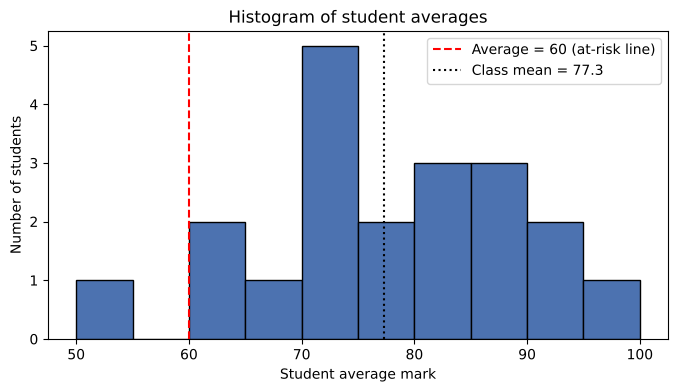

In [24]:
# Distribution of student averages (how the class is spread overall)
plt.figure(figsize=(8, 4))
plt.hist(student_mean, bins=np.arange(50, 101, 5), color="#4C72B0", edgecolor="black")
plt.axvline(60, color="red", ls="--", label="Average = 60 (at-risk line)")
plt.axvline(student_mean.mean(), color="black", ls=":", label=f"Class mean = {student_mean.mean():.1f}")
plt.xlabel("Student average mark")
plt.ylabel("Number of students")
plt.title("Histogram of student averages")
plt.legend()
plt.show()

### Findings from the plots
* **Averages are close together.** All subject means lie between **74.55 (Python)** and **79.65 (Research Methods)**, around the overall mean of 77.34.
* **Research Methods** has the **highest mean (79.65)** and the **smallest spread (SD 10.47, range 36)**. It is the strongest and most consistent subject.
* **Python** has the **lowest mean (74.55)** and the **largest spread (SD 13.02, CV 17.5%, range 46)**. Its box is the tallest and its lower whisker reaches 49, the only mark below the pass line of 50.
* **No outliers:** no points appear beyond the box-plot whiskers in any subject.
* **The heatmap shows horizontal bands.** A student who is strong in one subject is strong in all (S16, S8, S3, S13 are green throughout), and weak students are weak in all (S14, S4, S19, S10 are red/orange). Differences between *students* are much larger than differences between *subjects*. Student SDs are only 1.4 to 5.0, while subject SDs are 10 to 13.
* **Profiles are almost parallel** to the class-mean line. Most students dip slightly in Python.
* The histogram of averages shows most students between 70 and 92, with a small low tail (S14 at 54.8).

## (h) Interpretation and recommended academic interventions  *(10 marks)*
The cell below collects the evidence used in the interpretation.

In [25]:
weakest_subject_count = np.bincount(marks.argmin(axis=1), minlength=len(subjects))
print("Number of students whose LOWEST mark is in each subject:")
for s, c in zip(subjects, weakest_subject_count):
    print(f"   {s:20s}: {c}")

print("\nStudents with average >= 80 :", students[student_mean >= 80], f"({np.sum(student_mean >= 80)} students)")
print("Students with average  < 70 :", students[student_mean < 70], f"({np.sum(student_mean < 70)} students)")

print("\nCorrelation between subjects (rows/cols in subject order):")
print(np.corrcoef(marks.T).round(2))

Number of students whose LOWEST mark is in each subject:
   Python              : 10
   Statistics          : 4
   Data Visualization  : 3
   ML                  : 3
   Research Methods    : 0

Students with average >= 80 : ['S1' 'S3' 'S6' 'S8' 'S11' 'S13' 'S16' 'S18' 'S20'] (9 students)
Students with average  < 70 : ['S4' 'S10' 'S14' 'S19'] (4 students)

Correlation between subjects (rows/cols in subject order):
[[1.   0.97 0.98 0.96 0.98]
 [0.97 1.   0.96 0.94 0.96]
 [0.98 0.96 1.   0.91 0.98]
 [0.96 0.94 0.91 1.   0.9 ]
 [0.98 0.96 0.98 0.9  1.  ]]


### Interpretation

1. **Overall performance is good.** The class average is **77.34**. Nine students average 80 or more, and seven score at least 80 in *every* subject.
2. **Performance is driven by the student more than by the subject.** Subjects are very strongly correlated (r ≈ 0.90–0.98), and each student's marks vary by only about 1.4–5 points (student SD). Weak students are weak across the board, which suggests general gaps (study skills, prerequisites, attendance) rather than a problem in one course.
3. **Python is the weakest and most uneven subject.** It has the lowest mean (74.55), the largest SD (13.02) and the widest range (46), and it is the **lowest-scoring subject for 10 of the 20 students**. The large spread suggests that students arrive with very different programming backgrounds.
4. **Research Methods** has the highest and most consistent marks.
5. **At-risk students:**
   * **S14** is the highest-risk student. S14 is the only student with a mark below 50 (Python 49) and the only one with an average below 60 (54.8), and ranks last in every subject.
   * **S4 (60.0)** and **S19 (61.6)** are borderline. Both are just above the average-60 line, and their weakest subject is also Python.
   * **S10 (65.2)** is the next weakest and should be monitored.

### Recommended academic interventions

| Group | Intervention |
|---|---|
| **S14** (critical) | Individual remedial plan with a faculty mentor; Python bridging/remedial classes; weekly progress checks and a re-assessment opportunity. |
| **S4, S19** (borderline) and **S10** (watch) | Early-warning flag; peer tutoring (pair with a top student); extra practice sets in Python and Statistics; fortnightly check-ins. |
| **Python course** (all students) | Diagnostic programming test at the start; extra hands-on lab or coding clinic hours; graded weekly mini-exercises; differentiated assignments for beginners and advanced students. |
| **Top performers** S16, S8, S3, S13, S20 | Advanced projects or research tasks to keep them challenged; involve them as peer mentors. |
| **Monitoring** | Repeat this analysis after the next assessment and compare students using **z-scores**, which put all subjects on the same scale, to measure whether the interventions work. |

*Limitation:* these are 20 students and one set of marks. Treat the conclusions as indicative and confirm them with attendance data and later assessments before taking high-stakes decisions.